In [1]:
import pandas as pd
import glob
import matplotlib.pyplot as plt

In [2]:
files = sorted(glob.glob('../data/raw/*.csv'))
print(len(files))
demand = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

24


In [3]:
demand.head()

,REGION,SETTLEMENTDATE,TOTALDEMAND,RRP,PERIODTYPE
0,NSW1,2024/01/01 00:05:00,6574.92,57.98,TRADE
1,NSW1,2024/01/01 00:10:00,6651.09,70.27,TRADE
2,NSW1,2024/01/01 00:15:00,6538.96,57.98,TRADE
3,NSW1,2024/01/01 00:20:00,6497.99,54.95,TRADE
4,NSW1,2024/01/01 00:25:00,6404.55,54.95,TRADE


In [4]:
demand.shape

(210528, 5)

In [5]:
demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 5 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   REGION          210528 non-null  str    
 1   SETTLEMENTDATE  210528 non-null  str    
 2   TOTALDEMAND     210528 non-null  float64
 3   RRP             210528 non-null  float64
 4   PERIODTYPE      210528 non-null  str    
dtypes: float64(2), str(3)
memory usage: 8.0 MB


In [6]:
demand["SETTLEMENTDATE"] = pd.to_datetime(demand["SETTLEMENTDATE"])
demand = demand[["SETTLEMENTDATE", "TOTALDEMAND"]]
demand.info()

<class 'pandas.DataFrame'>
RangeIndex: 210528 entries, 0 to 210527
Data columns (total 2 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   SETTLEMENTDATE  210528 non-null  datetime64[us]
 1   TOTALDEMAND     210528 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 3.2 MB


In [7]:
daily = demand.set_index("SETTLEMENTDATE").resample("D").mean()

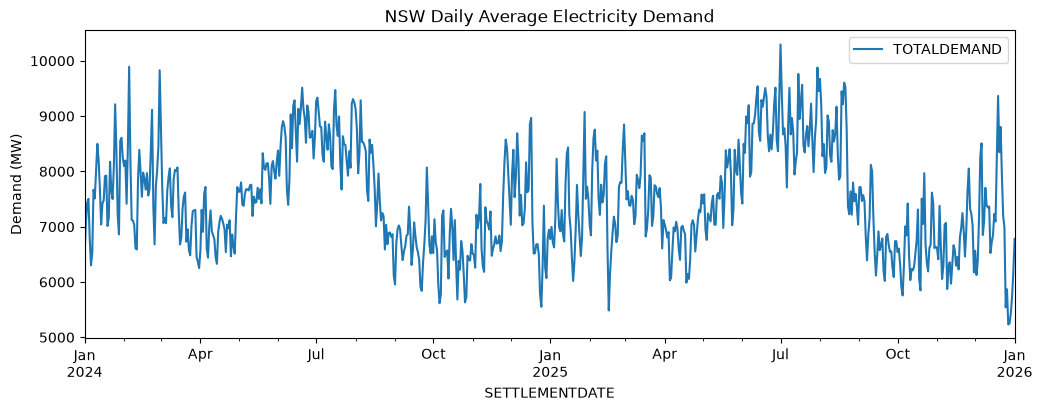

In [8]:
daily.plot(figsize=(12, 4), title="NSW Daily Average Electricity Demand")
plt.ylabel("Demand (MW)")
plt.show()

In [9]:
import json

with open("../data/raw/weather_sydney.json") as f:
    data = json.load(f)

weather = pd.DataFrame(data["hourly"])
weather.head()

,time,temperature_2m,relative_humidity_2m
0,2024-01-01T00:00,20.2,72
1,2024-01-01T01:00,19.7,79
2,2024-01-01T02:00,19.8,79
3,2024-01-01T03:00,19.4,83
4,2024-01-01T04:00,19.4,84


In [10]:
weather["time"] = pd.to_datetime(weather["time"])
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  17544 non-null  datetime64[us]
 1   temperature_2m        17544 non-null  float64       
 2   relative_humidity_2m  17544 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1)
memory usage: 411.3 KB


In [11]:
weather["time"] = pd.to_datetime(weather["time"])
weather.info()

<class 'pandas.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  17544 non-null  datetime64[us]
 1   temperature_2m        17544 non-null  float64       
 2   relative_humidity_2m  17544 non-null  int64         
dtypes: datetime64[us](1), float64(1), int64(1)
memory usage: 411.3 KB


In [12]:
hourly = demand.set_index("SETTLEMENTDATE").resample("h").mean()
hourly.head()

,TOTALDEMAND
SETTLEMENTDATE,
2024-01-01 00:00:00,6452.118182
2024-01-01 01:00:00,6133.330833
2024-01-01 02:00:00,5930.680000
2024-01-01 03:00:00,5821.847500
2024-01-01 04:00:00,5830.732500


In [13]:
weather = weather.set_index("time")
df = hourly.join(weather, how="inner")
df.head()

,TOTALDEMAND,temperature_2m,relative_humidity_2m
SETTLEMENTDATE,,,
2024-01-01 00:00:00,6452.118182,20.2,72
2024-01-01 01:00:00,6133.330833,19.7,79
2024-01-01 02:00:00,5930.680000,19.8,79
2024-01-01 03:00:00,5821.847500,19.4,83
2024-01-01 04:00:00,5830.732500,19.4,84


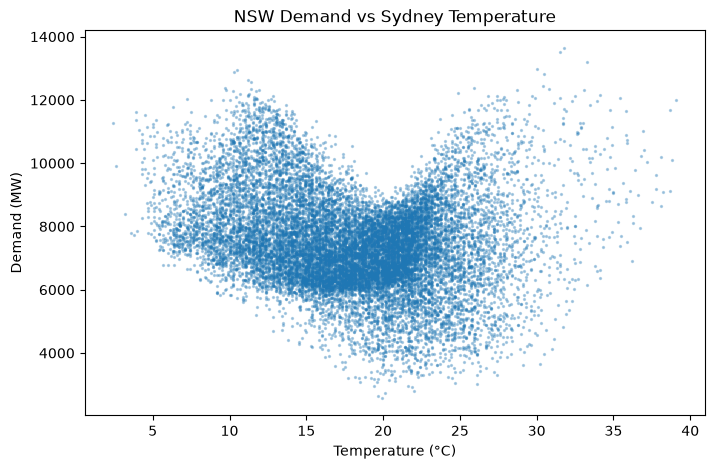

In [14]:
plt.figure(figsize=(8, 5))
plt.scatter(df["temperature_2m"], df["TOTALDEMAND"], s=2, alpha=0.3)
plt.xlabel("Temperature (°C)")
plt.ylabel("Demand (MW)")
plt.title("NSW Demand vs Sydney Temperature")
plt.show()